In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [ ]:
# Load and prepare the data
df = pd.read_csv('color_dataset_uno.csv')

# Separate features and labels
X = df[['red', 'green', 'blue']].values
y = df['label'].values

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

print(f"Number of classes: {num_classes}")
print(f"Classes: {label_encoder.classes_}")

Number of classes: 10
Classes: ['black' 'blue' 'green' 'orange' 'pink' 'purple' 'red' 'teal' 'white'
 'yellow']


In [ ]:
# Normalize the features (important for FPGA deployment)
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Convert to numpy arrays for TensorFlow
X_train = np.array(X_train, dtype=np.float32)
X_test = np.array(X_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.int32)
y_test = np.array(y_test, dtype=np.int32)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (400, 3)
Test set shape: (100, 3)


In [ ]:
# Create a resource-efficient model optimized for FPGA
def create_fpga_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        # Input layer
        tf.keras.layers.Dense(16, activation='relu', input_shape=input_shape,
                             kernel_regularizer=tf.keras.regularizers.l2(0.001)),
        tf.keras.layers.BatchNormalization(),

        # Hidden layer 1 - kept small for FPGA constraints
        tf.keras.layers.Dense(12, activation='relu',
                             kernel_regularizer=tf.keras.regularizers.l2(0.001)),
        tf.keras.layers.BatchNormalization(),

        # Hidden layer 2 - even smaller
        tf.keras.layers.Dense(8, activation='relu',
                             kernel_regularizer=tf.keras.regularizers.l2(0.001)),
        tf.keras.layers.BatchNormalization(),

        # Output layer - using sigmoid instead of softmax for FPGA efficiency
        # We'll use sigmoid and then normalize manually if needed
        tf.keras.layers.Dense(num_classes, activation='sigmoid')
    ])

    return model

In [ ]:
# Create model
input_shape = (X_train.shape[1],)
model = create_fpga_model(input_shape, num_classes)

# Custom training configuration for FPGA compatibility
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',  # Still use this loss, but sigmoid output
    metrics=['accuracy']
)

# Print model summary
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 12)             │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │            90 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 606 (2.37 KB)

 Trainable params: 534 (2.09 KB)

 Non-trainable params: 72 (288.00 B)

In [ ]:
# Calculate total parameters (important for FPGA resource estimation)
total_params = model.count_params()
print(f"Total parameters: {total_params}")

# Custom callback to monitor training
class FPGACallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch % 10 == 0:
            print(f"Epoch {epoch}: loss = {logs['loss']:.4f}, accuracy = {logs['accuracy']:.4f}")


Total parameters: 606


In [ ]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0,
    callbacks=[FPGACallback()]
)

Epoch 0: loss = 2.6094, accuracy = 0.1844
Epoch 10: loss = 1.2492, accuracy = 0.7250
Epoch 20: loss = 0.7940, accuracy = 0.9375
Epoch 30: loss = 0.5415, accuracy = 0.9719
Epoch 40: loss = 0.4297, accuracy = 0.9500
Epoch 50: loss = 0.2959, accuracy = 0.9812
Epoch 60: loss = 0.2188, accuracy = 0.9937
Epoch 70: loss = 0.1835, accuracy = 0.9781
Epoch 80: loss = 0.1661, accuracy = 0.9719
Epoch 90: loss = 0.1048, accuracy = 1.0000


In [ ]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_proba = model.predict(X_test)

# Convert sigmoid outputs to class predictions
# For multi-class with sigmoid, we take the argmax
y_pred = np.argmax(y_pred_proba, axis=1)

# Detailed evaluation
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Test Accuracy: 0.9800
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

Classification Report:
              precision    recall  f1-score   support

       black       1.00      1.00      1.00        10
        blue       0.91      1.00      0.95        10
       green       1.00      1.00      1.00        10
      orange       1.00      0.90      0.95        10
        pink       1.00      1.00      1.00        10
      purple       1.00      1.00      1.00        10
         red       1.00      1.00      1.00        10
        teal       1.00      0.90      0.95        10
       white       0.91      1.00      0.95        10
      yellow       1.00      1.00      1.00        10

    accuracy                           0.98       100
   macro avg       0.98      0.98      0.98       100
weighted avg       0.98      0.98      0.98       100



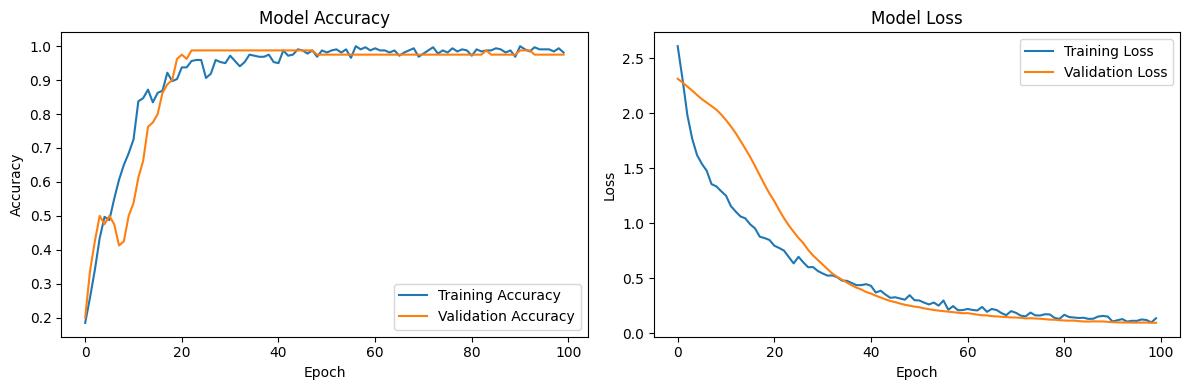

In [ ]:
# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Save the model in a format compatible with hls4ml
model.save('uno_color_classifier.h5')

# Save the scaler and label encoder for preprocessing in FPGA
import joblib
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(label_encoder, 'label_encoder.pkl')

print("\nModel and preprocessing objects saved successfully!")


Model and preprocessing objects saved successfully!


In [ ]:
# Additional analysis for FPGA deployment
print("\n=== FPGA Deployment Analysis ===")
print(f"Input features: {X_train.shape[1]}")
print(f"Output classes: {num_classes}")
print(f"Model parameters: {total_params}")

# Estimate model size (rough approximation)
model_size_bytes = total_params * 4  # Assuming 32-bit floats
print(f"Estimated model size: {model_size_bytes} bytes ({model_size_bytes/1024:.2f} KB)")

# Test with some sample data to verify functionality
print("\n=== Sample Predictions ===")
sample_indices = [0, 1, 2]
for idx in sample_indices:
    sample = X_test[idx:idx+1]
    prediction = model.predict(sample, verbose=0)
    predicted_class = np.argmax(prediction, axis=1)[0]
    actual_class = y_test[idx]

    print(f"Sample {idx}: Predicted = {label_encoder.classes_[predicted_class]}, "
          f"Actual = {label_encoder.classes_[actual_class]}")

# Create a simpler alternative model with even fewer parameters
def create_ultra_light_model(input_shape, num_classes):
    """Even more lightweight model for very constrained FPGAs"""
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(8, activation='relu', input_shape=input_shape),
        tf.keras.layers.Dense(6, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='sigmoid')
    ])
    return model

# Test the ultra-light model
ultra_light_model = create_ultra_light_model(input_shape, num_classes)
ultra_light_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

ultra_light_model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

ultra_light_accuracy = ultra_light_model.evaluate(X_test, y_test, verbose=0)[1]
print(f"\nUltra-light model accuracy: {ultra_light_accuracy:.4f}")
print(f"Ultra-light model parameters: {ultra_light_model.count_params()}")

# Save both models
ultra_light_model.save('color_classifier_ultra_light.h5')

print("\n=== Model Selection ===")
print(f"Standard model accuracy: {test_accuracy:.4f}, Parameters: {total_params}")
print(f"Ultra-light model accuracy: {ultra_light_accuracy:.4f}, Parameters: {ultra_light_model.count_params()}")

# Recommendation based on FPGA constraints
if total_params < 1000:  # Adjust based on your FPGA capacity
    recommended_model = "Standard model"
else:
    recommended_model = "Ultra-light model"

print(f"Recommended for Zybo Z7-10: {recommended_model}")


=== FPGA Deployment Analysis ===
Input features: 3
Output classes: 10
Model parameters: 606
Estimated model size: 2424 bytes (2.37 KB)

=== Sample Predictions ===
Sample 0: Predicted = red, Actual = red
Sample 1: Predicted = orange, Actual = orange
Sample 2: Predicted = red, Actual = red


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Ultra-light model accuracy: 0.5400
Ultra-light model parameters: 156

=== Model Selection ===
Standard model accuracy: 0.9800, Parameters: 606
Ultra-light model accuracy: 0.5400, Parameters: 156
Recommended for Zybo Z7-10: Standard model


In [ ]:
import joblib



scaler = joblib.load("scaler.pkl")

print("Scaler mean:", scaler.mean_)

print("Scaler scale (std):", scaler.scale_)

Scaler mean: [496.28  641.282 192.652]
Scaler scale (std): [481.60535047 478.45545506 217.77323733]


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Load and prepare data
df = pd.read_csv('color_dataset_uno.csv')
X = df[['red', 'green', 'blue']].values
y = df['label'].values

# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

# Normalize
scaler = StandardScaler()
X_normalized = scaler.fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Use the EXACT model that gave 98% accuracy
def create_high_accuracy_model(input_shape, num_classes):
    model = tf.keras.Sequential([
        # Original architecture that worked
        tf.keras.layers.Dense(16, activation='relu', input_shape=input_shape),
        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.Dense(12, activation='relu'),
        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.BatchNormalization(),

        # Softmax for high accuracy during training
        tf.keras.layers.Dense(num_classes, activation='softmax')
    ])
    return model

# Create and train
model = create_high_accuracy_model((3,), num_classes)

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train longer if needed
history = model.fit(
    X_train, y_train,
    epochs=150,  # More epochs for better convergence
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_accuracy:.4f}")

if test_accuracy >= 0.95:
    print("✓ High accuracy achieved! Proceeding with HLS conversion.")
    model.save('color_classifier_high_acc.h5')
    import joblib
    joblib.dump(scaler, 'scaler.pkl')
    joblib.dump(label_encoder, 'label_encoder.pkl')
else:
    print("✗ Accuracy too low. Adjust model architecture.")

Epoch 1/150


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.0222 - loss: 2.9559 - val_accuracy: 0.2250 - val_loss: 2.3577
Epoch 2/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0927 - loss: 2.5365 - val_accuracy: 0.1125 - val_loss: 2.3421
Epoch 3/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1803 - loss: 2.2085 - val_accuracy: 0.1000 - val_loss: 2.3213
Epoch 4/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3823 - loss: 1.9307 - val_accuracy: 0.1000 - val_loss: 2.2923
Epoch 5/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3601 - loss: 1.8481 - val_accuracy: 0.1875 - val_loss: 2.2717
Epoch 6/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4113 - loss: 1.8038 - val_accuracy: 0.1375 - val_loss: 2.2528
Epoch 7/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5828 - loss: 1.5299 - val_accuracy: 0.1250 - val_loss: 2.2343
Epoch 8/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6556 - loss: 1.3941 - val_accuracy: 0.1250 - val_loss: 

Test Accuracy: 0.9900
✓ High accuracy achieved! Proceeding with HLS conversion.
